In [1]:
import pandas as pd
import glob
import pycountry
import numpy as np

In [2]:
df_to_check=pd.read_csv("../newdata/named_cleaned_data.csv")
df_to_check.loc[df_to_check["Country Name"].str.contains("Germany"), "Mehrals1000Deutsche_boolean"] = True
df_to_check[df_to_check["Country Name"].str.contains("Germany")]["Mehrals1000Deutsche_boolean"]

137    True
Name: Mehrals1000Deutsche_boolean, dtype: bool

In [3]:
df_to_check=df_to_check.sort_values("Country Name").reset_index(drop=True)
df_to_check


,Country Name,Country Code,Land,BIP_rel_D,PurchasingPower_rel_D,Cost_BIP_Ratio,Bevoelkerungsdichte,Freedom_Score,PISA_Score,Sonnenstunde_pro_Tag,...,Healthcare,CostofLiving,LGBTQ,Mehrals5Morde_pro_100k_boolean,Mehrals1000Deutsche_boolean,Alkoholverbot_boolean,Kueste_boolean,Christian_boolean,Muslim_boolean,Jewish_boolean
0,Albania,ALB,Albanien,17.941915,55.228081,3.078160,100.217956,68.0,367.0,6.969863,...,73.22,1023.0,62.27,False,False,False,True,True,True,False
1,Algeria,DZA,Algerien,10.091681,41.567773,4.119014,19.382560,31.0,NaN,8.949315,...,72.93,467.0,3.72,False,False,False,True,False,True,False
2,Angola,AGO,Angola,3.803002,32.937121,8.660820,29.477746,28.0,NaN,6.413699,...,50.04,817.0,48.64,False,False,False,True,True,True,False
3,Argentina,ARG,Argentinien,24.835393,59.505221,2.395985,16.639956,85.0,395.0,6.083014,...,76.30,862.0,89.35,False,True,False,True,True,False,False
4,Armenia,ARM,Armenien,15.234000,48.258833,3.167837,105.119109,54.0,NaN,6.778082,...,73.65,1088.0,43.18,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,Uzbekistan,UZB,Usbekistan,5.666107,34.487384,6.086610,80.908447,12.0,352.0,7.321644,...,77.33,657.0,23.21,False,True,False,False,True,True,False
147,"Venezuela, RB",VEN,Venezuela,28.572670,80.986137,2.834392,32.085317,13.0,NaN,7.938836,...,72.49,823.0,50.00,True,True,False,True,True,False,False
148,Viet Nam,VNM,Vietnam,8.453892,37.302320,4.412443,320.175198,20.0,468.0,5.751712,...,77.29,616.0,52.27,False,False,False,True,True,False,False
149,Zambia,ZMB,Sambia,2.213405,37.886201,17.116708,27.877648,53.0,NaN,8.124566,...,59.51,811.0,4.88,True,False,False,False,True,False,False


In [4]:
df_to_check=df_to_check.drop_duplicates(subset=['Country Name'], keep='first')

In [5]:
df_to_check

,Country Name,Country Code,Land,BIP_rel_D,PurchasingPower_rel_D,Cost_BIP_Ratio,Bevoelkerungsdichte,Freedom_Score,PISA_Score,Sonnenstunde_pro_Tag,...,Healthcare,CostofLiving,LGBTQ,Mehrals5Morde_pro_100k_boolean,Mehrals1000Deutsche_boolean,Alkoholverbot_boolean,Kueste_boolean,Christian_boolean,Muslim_boolean,Jewish_boolean
0,Albania,ALB,Albanien,17.941915,55.228081,3.078160,100.217956,68.0,367.0,6.969863,...,73.22,1023.0,62.27,False,False,False,True,True,True,False
1,Algeria,DZA,Algerien,10.091681,41.567773,4.119014,19.382560,31.0,NaN,8.949315,...,72.93,467.0,3.72,False,False,False,True,False,True,False
2,Angola,AGO,Angola,3.803002,32.937121,8.660820,29.477746,28.0,NaN,6.413699,...,50.04,817.0,48.64,False,False,False,True,True,True,False
3,Argentina,ARG,Argentinien,24.835393,59.505221,2.395985,16.639956,85.0,395.0,6.083014,...,76.30,862.0,89.35,False,True,False,True,True,False,False
4,Armenia,ARM,Armenien,15.234000,48.258833,3.167837,105.119109,54.0,NaN,6.778082,...,73.65,1088.0,43.18,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,Uzbekistan,UZB,Usbekistan,5.666107,34.487384,6.086610,80.908447,12.0,352.0,7.321644,...,77.33,657.0,23.21,False,True,False,False,True,True,False
147,"Venezuela, RB",VEN,Venezuela,28.572670,80.986137,2.834392,32.085317,13.0,NaN,7.938836,...,72.49,823.0,50.00,True,True,False,True,True,False,False
148,Viet Nam,VNM,Vietnam,8.453892,37.302320,4.412443,320.175198,20.0,468.0,5.751712,...,77.29,616.0,52.27,False,False,False,True,True,False,False
149,Zambia,ZMB,Sambia,2.213405,37.886201,17.116708,27.877648,53.0,NaN,8.124566,...,59.51,811.0,4.88,True,False,False,False,True,False,False


In [6]:
safe_countries_enough_data_red=df_to_check.copy()

In [7]:
for col in safe_countries_enough_data_red.columns:
    print(col, safe_countries_enough_data_red[col].describe())
    print("--------------------")

Country Name count         150
unique        150
top       Albania
freq            1
Name: Country Name, dtype: object
--------------------
Country Code count     150
unique    150
top       ALB
freq        1
Name: Country Code, dtype: object
--------------------
Land count          150
unique         150
top       Albanien
freq             1
Name: Land, dtype: object
--------------------
BIP_rel_D count    150.000000
mean      34.517809
std       45.239934
min        0.275860
25%        4.778607
50%       14.455813
75%       46.355723
max      246.444528
Name: BIP_rel_D, dtype: float64
--------------------
PurchasingPower_rel_D count    149.000000
mean      60.660532
std       25.664092
min       16.235818
25%       42.430138
50%       53.390395
75%       73.836855
max      143.174683
Name: PurchasingPower_rel_D, dtype: float64
--------------------
Cost_BIP_Ratio count    149.000000
mean       7.656194
std       10.643705
min        0.479532
25%        1.465529
50%        3.363641
75%

In [8]:
safe_countries_enough_data_red.columns

Index(['Country Name', 'Country Code', 'Land', 'BIP_rel_D',
       'PurchasingPower_rel_D', 'Cost_BIP_Ratio', 'Bevoelkerungsdichte',
       'Freedom_Score', 'PISA_Score', 'Sonnenstunde_pro_Tag',
       'Zeitunterschied_D', 'Rang_Kueche', 'HoechsterPunkt_m',
       'NiedrigsterPunkt_m', 'EnglishSkill', 'BuerokratieScore',
       'MaxTemperatur', 'MinTemperatur', 'LivingConditions', 'Healthcare',
       'CostofLiving', 'LGBTQ', 'Mehrals5Morde_pro_100k_boolean',
       'Mehrals1000Deutsche_boolean', 'Alkoholverbot_boolean',
       'Kueste_boolean', 'Christian_boolean', 'Muslim_boolean',
       'Jewish_boolean'],
      dtype='object')

In [9]:
# here we create a dictionary for all indicators and all countries in the dataset
#which should be sorted first by countries, then by indicators

countries_dict={}
percentile_upper=90
percentile_lower=10
#so we go by each metric
for col in safe_countries_enough_data_red.columns[3:]:
    #if the metric is boolean
    if "boolean" in col:
        for iso3 in safe_countries_enough_data_red["Country Code"].tolist():
            print(iso3)
            #and the number of countries is more than one
            if (len(safe_countries_enough_data_red[safe_countries_enough_data_red["Country Code"]==iso3])>0):
                #we set the new inner dictionary accordingly, where both
                #the displayValue is the same as the binValue
                new_var={"id": col,
                "displayValue": bool(safe_countries_enough_data_red[safe_countries_enough_data_red["Country Code"]==iso3][col].values[0]),
                "binValue": bool(safe_countries_enough_data_red[safe_countries_enough_data_red["Country Code"]==iso3][col].values[0])
        }
            #if the country is already in the dictionary, we append the new variable
            if iso3 in countries_dict:
                #we retrieve the data for this country from the country dictionary
                saved_array=countries_dict[iso3]
                #we append the new variable to the country's array
                saved_array.append(new_var)
                countries_dict[iso3]=saved_array
            else:
                #otherwise we create a new entry for this country with the new variable as the first element in the array
                countries_dict[iso3]=[new_var]
    
    #if the metric is not boolean        
    else:
        print(col)

        # Get the 90th percentile value (upper 10%)
        threshold_upper = safe_countries_enough_data_red[col].quantile(percentile_upper*0.01).round(1)

        # Filter rows where column values are >= 90th percentile
        upper_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] >= threshold_upper]

        # Get the 10th percentile value (lower 10%)
        threshold_lower = safe_countries_enough_data_red[col].quantile(percentile_lower*0.01).round(1)

        # Filter rows where column values are <= 10th percentile
        lower_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] <= threshold_lower]

        #and we create a middle dataframe for the values in between the two thresholds
        middle_df=safe_countries_enough_data_red[safe_countries_enough_data_red[col] > threshold_lower]
        middle_df=middle_df[middle_df[col] < threshold_upper]
        
        #again we go through all countries
        for iso3 in safe_countries_enough_data_red["Country Code"].tolist():
            print(iso3)
            #and we check whether the counry is in the upper 10 percent
            #the lower 10 percent 
            # or the middle
            if (len(upper_10_percent[upper_10_percent["Country Code"]==iso3])>0):
                
                new_var={"id": col,
                "displayValue": float(np.ceil(upper_10_percent[upper_10_percent["Country Code"]==iso3][col].values[0]*10)/10),
                "binValue": float(threshold_upper.round(1))
        }

            if (len(lower_10_percent[lower_10_percent["Country Code"]==iso3])>0):
                new_var={"id": col,
                "displayValue": float(np.floor(lower_10_percent[lower_10_percent["Country Code"]==iso3][col].values[0]*10)/10),
                            "binValue": float(threshold_lower.round(1))
                    }
            if (len(middle_df[middle_df["Country Code"]==iso3])>0):
                new_var={"id": col,
                "displayValue": float(middle_df[middle_df["Country Code"]==iso3][col].values[0].round(1)),
                            "binValue": float(middle_df[middle_df["Country Code"]==iso3][col].values[0].round(1))
                    }
             #again here it is the same logic as above for how we 
             #store the data for each country in an array   
            if iso3 in countries_dict:
                saved_array=countries_dict[iso3]
                saved_array.append(new_var)
                countries_dict[iso3]=saved_array
            else:
                countries_dict[iso3]=[new_var]

countries_dict

BIP_rel_D
ALB
DZA
AGO
ARG
ARM
AUS
AUT
AZE
BHR
BGD
BEL
BLZ
BEN
BOL
BIH
BWA
BRA
BGR
BFA
BDI
CPV
KHM
CMR
CAN
TCD
CHL
CHN
COL
COM
COD
COG
CRI
CIV
HRV
CUB
CYP
CZE
DNK
DJI
DOM
ECU
EGY
SLV
GNQ
ERI
EST
SWZ
ETH
FIN
FRA
GAB
GMB
GEO
DEU
GHA
GRC
GTM
GIN
GNB
GUY
HND
HUN
ISL
IND
IDN
IRQ
IRL
ISR
ITA
JAM
JPN
JOR
KAZ
KEN
KOR
KWT
KGZ
LAO
LVA
LBN
LSO
LBR
LTU
LUX
MDG
MWI
MYS
MLT
MRT
MUS
MEX
MDA
MNG
MNE
MAR
MOZ
NAM
NPL
NLD
NZL
NIC
NGA
MKD
NOR
OMN
PAK
PAN
PNG
PRY
PER
PHL
POL
PRT
QAT
ROU
RUS
RWA
STP
SAU
SEN
SRB
SYC
SLE
SGP
SVK
SVN
ZAF
ESP
LKA
SUR
SWE
CHE
TJK
TZA
THA
TGO
TTO
TUN
TUR
TKM
UGA
ARE
GBR
USA
URY
UZB
VEN
VNM
ZMB
ZWE
PurchasingPower_rel_D
ALB
DZA
AGO
ARG
ARM
AUS
AUT
AZE
BHR
BGD
BEL
BLZ
BEN
BOL
BIH
BWA
BRA
BGR
BFA
BDI
CPV
KHM
CMR
CAN
TCD
CHL
CHN
COL
COM
COD
COG
CRI
CIV
HRV
CUB
CYP
CZE
DNK
DJI
DOM
ECU
EGY
SLV
GNQ
ERI
EST
SWZ
ETH
FIN
FRA
GAB
GMB
GEO
DEU
GHA
GRC
GTM
GIN
GNB
GUY
HND
HUN
ISL
IND
IDN
IRQ
IRL
ISR
ITA
JAM
JPN
JOR
KAZ
KEN
KOR
KWT
KGZ
LAO
LVA
LBN
LSO
LBR
LTU
LUX
MDG
MWI
MYS
MLT
MRT
MUS
MEX
MDA


{'ALB': [{'id': 'BIP_rel_D', 'displayValue': 17.9, 'binValue': 17.9},
  {'id': 'PurchasingPower_rel_D', 'displayValue': 55.2, 'binValue': 55.2},
  {'id': 'Cost_BIP_Ratio', 'displayValue': 3.1, 'binValue': 3.1},
  {'id': 'Bevoelkerungsdichte', 'displayValue': 100.2, 'binValue': 100.2},
  {'id': 'Freedom_Score', 'displayValue': 68.0, 'binValue': 68.0},
  {'id': 'PISA_Score', 'displayValue': 367.0, 'binValue': 367.0},
  {'id': 'Sonnenstunde_pro_Tag', 'displayValue': 7.0, 'binValue': 7.0},
  {'id': 'Zeitunterschied_D', 'displayValue': 0.0, 'binValue': 0.0},
  {'id': 'Rang_Kueche', 'displayValue': 77.0, 'binValue': 77.0},
  {'id': 'HoechsterPunkt_m', 'displayValue': 2764.0, 'binValue': 2764.0},
  {'id': 'NiedrigsterPunkt_m', 'displayValue': 0.0, 'binValue': 0.0},
  {'id': 'EnglishSkill', 'displayValue': 533.0, 'binValue': 533.0},
  {'id': 'BuerokratieScore', 'displayValue': 0.3, 'binValue': 0.3},
  {'id': 'MaxTemperatur', 'displayValue': 31.2, 'binValue': 31.2},
  {'id': 'MinTemperatur', 'd

In [10]:
countries_dict

{'ALB': [{'id': 'BIP_rel_D', 'displayValue': 17.9, 'binValue': 17.9},
  {'id': 'PurchasingPower_rel_D', 'displayValue': 55.2, 'binValue': 55.2},
  {'id': 'Cost_BIP_Ratio', 'displayValue': 3.1, 'binValue': 3.1},
  {'id': 'Bevoelkerungsdichte', 'displayValue': 100.2, 'binValue': 100.2},
  {'id': 'Freedom_Score', 'displayValue': 68.0, 'binValue': 68.0},
  {'id': 'PISA_Score', 'displayValue': 367.0, 'binValue': 367.0},
  {'id': 'Sonnenstunde_pro_Tag', 'displayValue': 7.0, 'binValue': 7.0},
  {'id': 'Zeitunterschied_D', 'displayValue': 0.0, 'binValue': 0.0},
  {'id': 'Rang_Kueche', 'displayValue': 77.0, 'binValue': 77.0},
  {'id': 'HoechsterPunkt_m', 'displayValue': 2764.0, 'binValue': 2764.0},
  {'id': 'NiedrigsterPunkt_m', 'displayValue': 0.0, 'binValue': 0.0},
  {'id': 'EnglishSkill', 'displayValue': 533.0, 'binValue': 533.0},
  {'id': 'BuerokratieScore', 'displayValue': 0.3, 'binValue': 0.3},
  {'id': 'MaxTemperatur', 'displayValue': 31.2, 'binValue': 31.2},
  {'id': 'MinTemperatur', 'd

In [11]:
def skew_trimmer(col):

    safe_countries_enough_data_red[col]

    # Get the 90th percentile value (upper 10%)
    threshold_upper = safe_countries_enough_data_red[col].quantile(percentile_upper*0.01).round(1)

    # Filter rows where column values are >= 90th percentile
    upper_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] >= threshold_upper]

    # Get the 90th percentile value (upper 10%)
    threshold_lower = safe_countries_enough_data_red[col].quantile(percentile_lower*0.01).round(1)

    # Filter rows where column values are >= 90th percentile
    lower_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] <= threshold_lower]
    
    middle_df=safe_countries_enough_data_red[safe_countries_enough_data_red[col] > threshold_lower]
    middle_df=middle_df[middle_df[col] < threshold_upper]
    return(middle_df, threshold_upper,threshold_lower)

In [12]:
boundaries_dict={}
for col in safe_countries_enough_data_red.columns[3:]:
    if "boolean" in col:
        boundaries_dict[col]={}
    else:
        results_list=skew_trimmer(col)
        boundaries_dict[col]={"upper":float(results_list[1]),
                              "lower":float(results_list[2])}

In [13]:
boundaries_dict

{'BIP_rel_D': {'upper': 97.6, 'lower': 1.8},
 'PurchasingPower_rel_D': {'upper': 103.2, 'lower': 35.8},
 'Cost_BIP_Ratio': {'upper': 20.6, 'lower': 1.0},
 'Bevoelkerungsdichte': {'upper': 359.1, 'lower': 15.6},
 'Freedom_Score': {'upper': 96.0, 'lower': 15.0},
 'PISA_Score': {'upper': 496.4, 'lower': 361.2},
 'Sonnenstunde_pro_Tag': {'upper': 8.9, 'lower': 4.8},
 'Zeitunterschied_D': {'upper': 7.0, 'lower': 0.0},
 'Rang_Kueche': {'upper': 91.2, 'lower': 9.8},
 'HoechsterPunkt_m': {'upper': 5787.0, 'lower': 656.0},
 'NiedrigsterPunkt_m': {'upper': 116.8, 'lower': -28.6},
 'EnglishSkill': {'upper': 594.8, 'lower': 428.6},
 'BuerokratieScore': {'upper': 1.4, 'lower': -1.1},
 'MaxTemperatur': {'upper': 40.3, 'lower': 26.5},
 'MinTemperatur': {'upper': 18.0, 'lower': -15.9},
 'LivingConditions': {'upper': 93.9, 'lower': 42.9},
 'Healthcare': {'upper': 81.8, 'lower': 52.5},
 'CostofLiving': {'upper': 1873.6, 'lower': 556.7},
 'LGBTQ': {'upper': 88.7, 'lower': 5.6},
 'Mehrals5Morde_pro_100k_b

Bin edges: [ 1.8  8.2 14.5 20.9 27.3 33.6 40.  46.4 52.7 59.1 65.5 71.8 78.2 84.6
 90.9 97.3]
Bin counts: [41. 20. 12.  9.  6.  4.  6.  3.  6.  4.  1.  2.  1.  2.  4.]
Number of bins: 15
Bin edges: [ 35.8  40.3  44.8  49.2  53.7  58.2  62.6  67.1  71.6  76.   80.5  85.
  89.4  93.9  98.4 102.8]
Bin counts: [14. 20. 15. 11. 11.  9.  6.  6.  5.  7.  8.  3.  0.  1.  3.]
Number of bins: 15
Bin edges: [ 1.   2.3  3.6  4.9  6.2  7.5  8.8 10.1 11.4 12.7 14.  15.3 16.7 18.
 19.3 20.6]
Bin counts: [44. 20. 13. 10.  7.  2.  7.  3.  3.  2.  2.  2.  3.  1.  2.]
Number of bins: 15
Bin edges: [ 15.7  38.4  61.1  83.8 106.5 129.2 151.9 174.6 197.3 220.  242.7 265.4
 288.1 310.8 333.5 356.2]
Bin counts: [25. 15. 18. 16. 13.  9.  2.  0.  2.  7.  4.  4.  1.  2.  2.]
Number of bins: 15
Bin edges: [17.  22.2 27.4 32.6 37.8 43.  48.2 53.4 58.6 63.8 69.  74.2 79.4 84.6
 89.8 95. ]
Bin counts: [ 9.  8.  6.  6.  6.  7.  6.  7.  8. 10.  7.  2. 14. 10. 11.]
Number of bins: 15
Bin edges: [364.  372.7 381.5 390.2

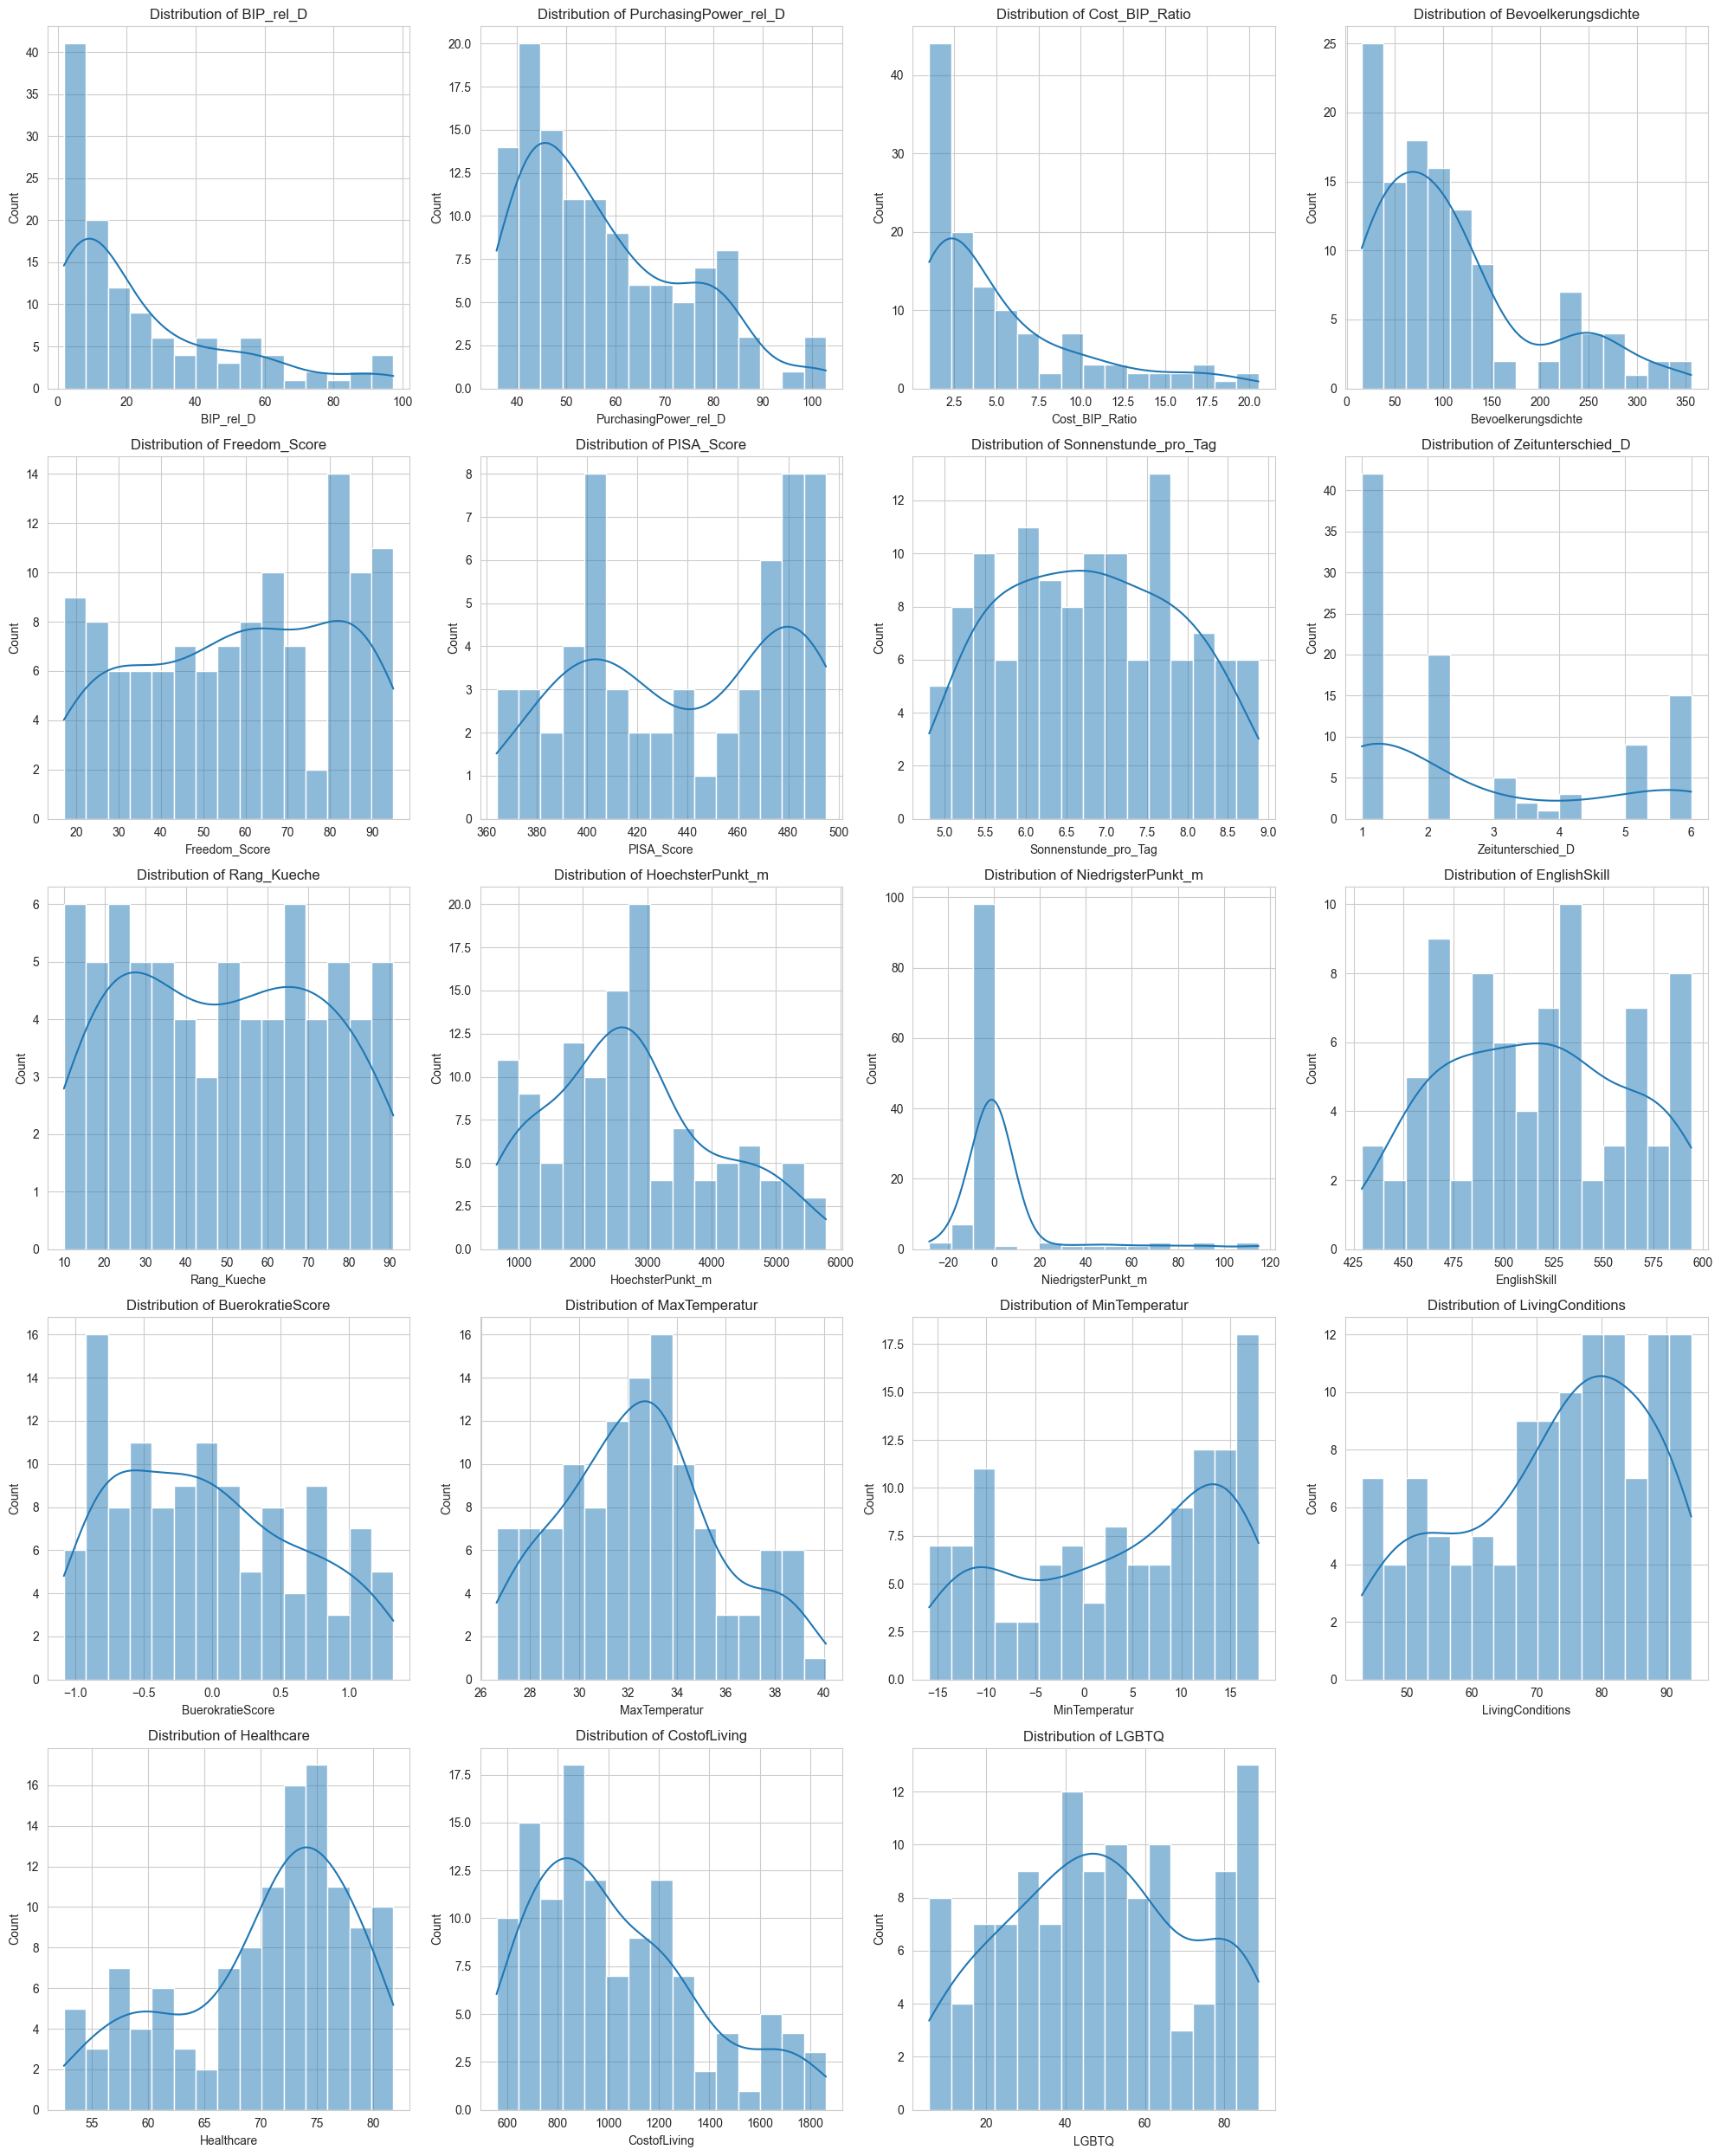

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set style
sns.set_style("whitegrid")

# Get numeric columns
numeric_cols = safe_countries_enough_data_red.select_dtypes(include=[np.number]).columns

# Create subplots
n_cols = 4
n_rows = len(numeric_cols) // n_cols + (1 if len(numeric_cols) % n_cols > 0 else 0)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5*n_rows))
axes = axes.flatten() if n_rows > 1 else [axes] if n_cols == 1 else axes
edges_dict={}
for i, col in enumerate(numeric_cols):
    df_to_plot=skew_trimmer(col)[0]
    sns.histplot(data=df_to_plot, x=col, ax=axes[i], kde=1, bins=15)
    axes[i].set_title(f'Distribution of {col}')
    # Create histogram and capture the bin information
    data = df_to_plot[col].dropna()

# Create histogram and capture the bin information
    counts, bin_edges, patches = plt.hist(data, bins=15)
    bin_edges = bin_edges.round(1)
    edges_dict[col]=bin_edges
    print(f"Bin edges: {bin_edges}")
    print(f"Bin counts: {counts}")
    print(f"Number of bins: {len(bin_edges) - 1}")



# Hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [15]:
# First install the library if you haven't: pip install pycountry-convert
import pycountry_convert as pc

def get_continent_from_iso3(iso3_code):
    """
    Convert ISO-3 country code to continent name
    """
    try:
        # Convert ISO3 to ISO2
        iso2_code = pc.country_alpha3_to_country_alpha2(iso3_code)
        # Get continent code
        continent_code = pc.country_alpha2_to_continent_code(iso2_code)
        # Convert continent code to continent name
        continent_name = pc.convert_continent_code_to_continent_name(continent_code)
        return continent_name
    except:
        return "Unknown"

# Test with some examples
test_codes = ['USA', 'GBR', 'DEU', 'JPN', 'BRA', 'EGY', 'AUS']
for code in test_codes:
    continent = get_continent_from_iso3(code)
    print(f"{code}: {continent}")

USA: North America
GBR: Europe
DEU: Europe
JPN: Asia
BRA: South America
EGY: Africa
AUS: Oceania


In [16]:
english_to_german_continents = {
    'Europe': 'Europa',
    'North America': 'Nordamerika', 
    'South America': 'Südamerika',
    'Asia': 'Asien',
    'Africa': 'Afrika',
    'Oceania': 'Ozeanien',
    'Antarctica': 'Antarktis',
    'Unknown': 'Unbekannt'
}

In [18]:
country_info_json=[]
for isocode in countries_dict.keys():
    print(isocode)
    continent=get_continent_from_iso3(isocode)
    land=df_to_check[df_to_check["Country Code"]==isocode]["Land"].values[0]
    country_name=df_to_check[df_to_check["Country Code"]==isocode]["Country Name"].values[0]
    german_continent_name=english_to_german_continents[continent]
    country_entry={"id":isocode,"label":land,"country":country_name,"groupID":german_continent_name,"output":countries_dict[isocode]}
    country_info_json.append(country_entry)
country_info_json


ALB
DZA
AGO
ARG
ARM
AUS
AUT
AZE
BHR
BGD
BEL
BLZ
BEN
BOL
BIH
BWA
BRA
BGR
BFA
BDI
CPV
KHM
CMR
CAN
TCD
CHL
CHN
COL
COM
COD
COG
CRI
CIV
HRV
CUB
CYP
CZE
DNK
DJI
DOM
ECU
EGY
SLV
GNQ
ERI
EST
SWZ
ETH
FIN
FRA
GAB
GMB
GEO
DEU
GHA
GRC
GTM
GIN
GNB
GUY
HND
HUN
ISL
IND
IDN
IRQ
IRL
ISR
ITA
JAM
JPN
JOR
KAZ
KEN
KOR
KWT
KGZ
LAO
LVA
LBN
LSO
LBR
LTU
LUX
MDG
MWI
MYS
MLT
MRT
MUS
MEX
MDA
MNG
MNE
MAR
MOZ
NAM
NPL
NLD
NZL
NIC
NGA
MKD
NOR
OMN
PAK
PAN
PNG
PRY
PER
PHL
POL
PRT
QAT
ROU
RUS
RWA
STP
SAU
SEN
SRB
SYC
SLE
SGP
SVK
SVN
ZAF
ESP
LKA
SUR
SWE
CHE
TJK
TZA
THA
TGO
TTO
TUN
TUR
TKM
UGA
ARE
GBR
USA
URY
UZB
VEN
VNM
ZMB
ZWE


[{'id': 'ALB',
  'label': 'Albanien',
  'country': 'Albania',
  'groupID': 'Europa',
  'output': [{'id': 'BIP_rel_D', 'displayValue': 17.9, 'binValue': 17.9},
   {'id': 'PurchasingPower_rel_D', 'displayValue': 55.2, 'binValue': 55.2},
   {'id': 'Cost_BIP_Ratio', 'displayValue': 3.1, 'binValue': 3.1},
   {'id': 'Bevoelkerungsdichte', 'displayValue': 100.2, 'binValue': 100.2},
   {'id': 'Freedom_Score', 'displayValue': 68.0, 'binValue': 68.0},
   {'id': 'PISA_Score', 'displayValue': 367.0, 'binValue': 367.0},
   {'id': 'Sonnenstunde_pro_Tag', 'displayValue': 7.0, 'binValue': 7.0},
   {'id': 'Zeitunterschied_D', 'displayValue': 0.0, 'binValue': 0.0},
   {'id': 'Rang_Kueche', 'displayValue': 77.0, 'binValue': 77.0},
   {'id': 'HoechsterPunkt_m', 'displayValue': 2764.0, 'binValue': 2764.0},
   {'id': 'NiedrigsterPunkt_m', 'displayValue': 0.0, 'binValue': 0.0},
   {'id': 'EnglishSkill', 'displayValue': 533.0, 'binValue': 533.0},
   {'id': 'BuerokratieScore', 'displayValue': 0.3, 'binValue': 

In [19]:
import json

# Write with nice formatting
with open('country_info_formatted_jan.json', 'w', encoding='utf-8') as f:
    json.dump(country_info_json, f, 
              indent=4,           # 4-space indentation
              ensure_ascii=False, # Keep unicode characters (like ä, ü, ö)
              sort_keys=1)     # Sort keys alphabetically

print("Formatted JSON file saved!")

Formatted JSON file saved!


In [20]:
safe_countries_enough_data_red.columns

Index(['Country Name', 'Country Code', 'Land', 'BIP_rel_D',
       'PurchasingPower_rel_D', 'Cost_BIP_Ratio', 'Bevoelkerungsdichte',
       'Freedom_Score', 'PISA_Score', 'Sonnenstunde_pro_Tag',
       'Zeitunterschied_D', 'Rang_Kueche', 'HoechsterPunkt_m',
       'NiedrigsterPunkt_m', 'EnglishSkill', 'BuerokratieScore',
       'MaxTemperatur', 'MinTemperatur', 'LivingConditions', 'Healthcare',
       'CostofLiving', 'LGBTQ', 'Mehrals5Morde_pro_100k_boolean',
       'Mehrals1000Deutsche_boolean', 'Alkoholverbot_boolean',
       'Kueste_boolean', 'Christian_boolean', 'Muslim_boolean',
       'Jewish_boolean'],
      dtype='object')

In [21]:
# Fixed version - use lists as VALUES, not wrapped in sets
classifier_dict = {
    "Geografie/Klima": [
        'Sonnenstunde_pro_Tag', 'Kueste_boolean', 'HoechsterPunkt_m', 
        'NiedrigsterPunkt_m', 'MaxTemperatur', 'MinTemperatur', 'Zeitunterschied_D'
    ],
    
    "Wirtschaftslage/Gesundheit": [
        'BIP_rel_D', 'PurchasingPower_rel_D', 'Cost_BIP_Ratio', 
        'CostofLiving', 'LivingConditions', 'Healthcare'
    ],
    
    "Freiheit/Sicherheit": [
        'Mehrals5Morde_pro_100k_boolean', 'Freedom_Score', 'BuerokratieScore', 'LGBTQ', 'Alkoholverbot_boolean'
    ],
    
    "Menschen/Religion": [
        'Bevoelkerungsdichte', 'PISA_Score', 'Rang_Kueche', 
        'EnglishSkill', 'Mehrals1000Deutsche_boolean','Christian_boolean', 'Muslim_boolean',
        'Jewish_boolean'
    ]
}

print(classifier_dict)

{'Geografie/Klima': ['Sonnenstunde_pro_Tag', 'Kueste_boolean', 'HoechsterPunkt_m', 'NiedrigsterPunkt_m', 'MaxTemperatur', 'MinTemperatur', 'Zeitunterschied_D'], 'Wirtschaftslage/Gesundheit': ['BIP_rel_D', 'PurchasingPower_rel_D', 'Cost_BIP_Ratio', 'CostofLiving', 'LivingConditions', 'Healthcare'], 'Freiheit/Sicherheit': ['Mehrals5Morde_pro_100k_boolean', 'Freedom_Score', 'BuerokratieScore', 'LGBTQ', 'Alkoholverbot_boolean'], 'Menschen/Religion': ['Bevoelkerungsdichte', 'PISA_Score', 'Rang_Kueche', 'EnglishSkill', 'Mehrals1000Deutsche_boolean', 'Christian_boolean', 'Muslim_boolean', 'Jewish_boolean']}


In [22]:
# Create a reverse mapping: column -> category
column_to_category = {}
for category, columns in classifier_dict.items():
    for column in columns:
        column_to_category[column] = category

print("Column to Category mapping:")
print(column_to_category)

Column to Category mapping:
{'Sonnenstunde_pro_Tag': 'Geografie/Klima', 'Kueste_boolean': 'Geografie/Klima', 'HoechsterPunkt_m': 'Geografie/Klima', 'NiedrigsterPunkt_m': 'Geografie/Klima', 'MaxTemperatur': 'Geografie/Klima', 'MinTemperatur': 'Geografie/Klima', 'Zeitunterschied_D': 'Geografie/Klima', 'BIP_rel_D': 'Wirtschaftslage/Gesundheit', 'PurchasingPower_rel_D': 'Wirtschaftslage/Gesundheit', 'Cost_BIP_Ratio': 'Wirtschaftslage/Gesundheit', 'CostofLiving': 'Wirtschaftslage/Gesundheit', 'LivingConditions': 'Wirtschaftslage/Gesundheit', 'Healthcare': 'Wirtschaftslage/Gesundheit', 'Mehrals5Morde_pro_100k_boolean': 'Freiheit/Sicherheit', 'Freedom_Score': 'Freiheit/Sicherheit', 'BuerokratieScore': 'Freiheit/Sicherheit', 'LGBTQ': 'Freiheit/Sicherheit', 'Alkoholverbot_boolean': 'Freiheit/Sicherheit', 'Bevoelkerungsdichte': 'Menschen/Religion', 'PISA_Score': 'Menschen/Religion', 'Rang_Kueche': 'Menschen/Religion', 'EnglishSkill': 'Menschen/Religion', 'Mehrals1000Deutsche_boolean': 'Menschen/

In [23]:
id_title={'Sonnenstunde_pro_Tag': 'Durchschnittliche Sonnenstunden pro Tag',
  'Kueste_boolean': 'Meeresküste', 
  'HoechsterPunkt_m': 'Höchster Punkt des Landes', 
  'NiedrigsterPunkt_m': "Niedrigster Punkt des Landes", 
  'MaxTemperatur': 'Maximale mittlere Monatstemperatur', 
  'MinTemperatur': 'Minimale mittlere Monatstemperatur', 
  'Zeitunterschied_D': 'Zeitverschiebung zu Deutschland', 
  'BIP_rel_D': 'Bruttoinlandsprodukt im Vergleich zu Deutschland', 
  'PurchasingPower_rel_D': 'Kaufkraft im Vergleich zu Deutschland', 
  'Cost_BIP_Ratio': 'Verhältnis Kaufkraft zu Bruttoinlandsprodukt', 
  'CostofLiving': 'Lebenshaltungskosten im Land', 
  'LivingConditions': 'Lebensbedingungen im Land', 
  'Healthcare': 'Qualität des Gesundheitssystems', 
  'Christian_boolean': 'Christliche Bevölkerung', 
  'Muslim_boolean': 'Muslimische Bevölkerung', 
  'Jewish_boolean': 'Jüdische Bevölkerung', 
  'Mehrals5Morde_pro_100k_boolean': 'Hohe Zahl an Morden', 
  'Freedom_Score': 'Freiheit-Score von Freedom House', 
  'BuerokratieScore': 'Bürokratie-Score der Weltbank', 
  'LGBTQ': 'LGBTQ-Rechte-Index von EqualDex ', 
  'Alkoholverbot_boolean': 'Striktes Alkoholverbot', 
  'Bevoelkerungsdichte': 'Bevölkerungsdichte', 
  'PISA_Score': 'PISA-Durchschnitt 2022', 
  'Rang_Kueche': 'Ranking der Küche von Taste Atlas', 
  'EnglishSkill': 'Englisch-Skills gemäß EF', 
  'Mehrals1000Deutsche_boolean': 'Mehr als 1000 Deutsche im Land'}


In [24]:
id_einheit={'Sonnenstunde_pro_Tag': 'h/Tag',
            'Kueste_boolean': 'Nein/Ja',
  'HoechsterPunkt_m': 'm', 
  'NiedrigsterPunkt_m': 'm', 
  'MaxTemperatur': '°C', 
  'MinTemperatur': '°C', 
  'Zeitunterschied_D': 'h', 
  'BIP_rel_D': '%', 
  'PurchasingPower_rel_D': '%', 
  'Cost_BIP_Ratio': 'Ratio', 
  'CostofLiving': '$', 
  'LivingConditions': 'Indexpunkte', 
  'Healthcare': 'Indexpunkte', 
  'Freedom_Score': 'Indexpunkte', 
  'BuerokratieScore': 'Indexpunkte', 
  'LGBTQ': 'Indexpunkte', 
  'Alkoholverbot': 'Nein/Ja', 
  'Bevoelkerungsdichte': 'Ew./km2', 
  'PISA_Score': 'Indexpunkte', 
  'Rang_Kueche': 'Rang', 
  'EnglishSkill': 'Indexpunkte', 
  'Anzahl_der_Deutschen_numeric': 'Ew.',
  'Christian_boolean': 'Nein/Ja', 
  'Muslim_boolean': 'Nein/Ja', 
  'Jewish_boolean': 'Nein/Ja', 
  'Mehrals5Morde_pro_100k_boolean': 'Nein/Ja', 
    'Alkoholverbot_boolean': 'Nein/Ja', 
    "Mehrals1000Deutsche_boolean": 'Nein/Ja'}

In [25]:
id_descript={'Sonnenstunde_pro_Tag': 'Wie viel Sonnenstunden gibt es durchschnittlich pro Tag?',
            'Kueste_boolean': 'Hat das Land eine Meeresküste?',
  'HoechsterPunkt_m': 'Was ist der höchste Punkt des Landes?', 
  'NiedrigsterPunkt_m': 'Was ist der niedrigste Punkt des Landes?', 
  'MaxTemperatur': 'Was ist die höchste Maximaltemperatur auf Monatsbasis?', 
  'MinTemperatur': 'Was ist die niedrigste Minimaltemperatur auf Monatsbasis?', 
  'Zeitunterschied_D': 'Was ist der Zeitunterschied zu Deutschland?', 
  'BIP_rel_D': 'Wie groß ist das BIP im Vergleich zu Deutschland?', 
  'PurchasingPower_rel_D': 'Wie groß ist die Kaufkraft im Vergleich zu Deutschland?', 
  'Cost_BIP_Ratio': 'Was ist das Verhältnis der Kosten zum BIP?', 
  'CostofLiving': 'Was sind die Lebenshaltungskosten in US-Dollar?', 
  'LivingConditions': 'Wo liegen die Lebensbedingungen in Indexpunkten des Legatum Institut?', 
  'Healthcare': 'Wo liegt die Gesundheitsversorgung in Indexpunkten des Legatum Institut?', 
  'Freedom_Score': 'Wo liegen die bürgerlichen Freiheiten in Indexpunkten des Freedom House Institut?', 
  'BuerokratieScore': 'Wo liegt die Ordnung und Bürokratie in Indexpunkten der OECD? (je höher desto besser))', 
  'LGBTQ': 'Wo liegen die LGBTQ-Rechte in Indexpunkten des EqualDex Instituts?', 
  'Alkoholverbot': 'Herrscht ein striktes Alkoholverbot im Land?',  
  'Bevoelkerungsdichte': 'Wie viele Einwohner gibt es pro km2?', 
  'PISA_Score': 'Wie gut sind die PISA-Ergebnisse im Durchschnitt (2022)?', 
  'Rang_Kueche': 'Wie gut wird die Küche des Landes bei Taste Atlas bewertet?', 
  'EnglishSkill': 'Wie gut sind die Englischkenntnisse in der Bevölkerung gemäß Education First?', 
  'Anzahl_der_Deutschen_numeric': 'Wie viele Deutsche leben im Land?', 
  'Christian_boolean': 'Gibt es einen nennenswerten christlichen Bevölkerungsanteil?', 
  'Muslim_boolean': 'Gibt es einen nennenswerten muslimischen Bevölkerungsanteil?', 
  'Jewish_boolean': 'Gibt es einen nennenswerten jüdischen Bevölkerungsanteil?', 
  'Mehrals5Morde_pro_100k_boolean': 'Gibt es mehr als 5 Morde pro 100.000 Einwohner?', 
    'Alkoholverbot_boolean': 'Herrscht ein striktes Alkoholverbot im Land?', 
    "Mehrals1000Deutsche_boolean": 'Leben mehr als 1000 Deutsche im Land?'}

In [26]:
boundaries_dict

{'BIP_rel_D': {'upper': 97.6, 'lower': 1.8},
 'PurchasingPower_rel_D': {'upper': 103.2, 'lower': 35.8},
 'Cost_BIP_Ratio': {'upper': 20.6, 'lower': 1.0},
 'Bevoelkerungsdichte': {'upper': 359.1, 'lower': 15.6},
 'Freedom_Score': {'upper': 96.0, 'lower': 15.0},
 'PISA_Score': {'upper': 496.4, 'lower': 361.2},
 'Sonnenstunde_pro_Tag': {'upper': 8.9, 'lower': 4.8},
 'Zeitunterschied_D': {'upper': 7.0, 'lower': 0.0},
 'Rang_Kueche': {'upper': 91.2, 'lower': 9.8},
 'HoechsterPunkt_m': {'upper': 5787.0, 'lower': 656.0},
 'NiedrigsterPunkt_m': {'upper': 116.8, 'lower': -28.6},
 'EnglishSkill': {'upper': 594.8, 'lower': 428.6},
 'BuerokratieScore': {'upper': 1.4, 'lower': -1.1},
 'MaxTemperatur': {'upper': 40.3, 'lower': 26.5},
 'MinTemperatur': {'upper': 18.0, 'lower': -15.9},
 'LivingConditions': {'upper': 93.9, 'lower': 42.9},
 'Healthcare': {'upper': 81.8, 'lower': 52.5},
 'CostofLiving': {'upper': 1873.6, 'lower': 556.7},
 'LGBTQ': {'upper': 88.7, 'lower': 5.6},
 'Mehrals5Morde_pro_100k_b

In [27]:
colour_category_dict={
    "Geografie/Klima": "yellow",
    "Wirtschaftslage/Gesundheit": "green",  
    "Freiheit/Sicherheit": "blue",  
    "Menschen/Religion": "orange"}

In [28]:
input_json=[]
for category in classifier_dict.keys():
    print(category)
    print(classifier_dict[category])
    items_json=[]
    for item in classifier_dict[category]:
        #print(item)
        #print(category)
        if "_boolean" in item:
            filtertype="boolean"
            category_input={
            "type": filtertype,
            "id": item,
            "title": id_title[item],
            "description": id_descript[item],
            "color": colour_category_dict[category]
           
            }
        else:
            filtertype="slider"
            category_input={
            "type": filtertype,
            "id": item,
            "title": id_title[item],
            "description": id_descript[item],

            "color": colour_category_dict[category],
            "filter": {
            "min":boundaries_dict[item]["lower"],
            "max": boundaries_dict[item]["upper"],

            "threshold": edges_dict[item].tolist(),
            "unit": id_einheit[item]
            }
  
    }
        items_json.append(category_input)
    input_json.append({
        "title": category,
        "color": colour_category_dict[category],
        "items": items_json
    })
input_json
        

Geografie/Klima
['Sonnenstunde_pro_Tag', 'Kueste_boolean', 'HoechsterPunkt_m', 'NiedrigsterPunkt_m', 'MaxTemperatur', 'MinTemperatur', 'Zeitunterschied_D']
Wirtschaftslage/Gesundheit
['BIP_rel_D', 'PurchasingPower_rel_D', 'Cost_BIP_Ratio', 'CostofLiving', 'LivingConditions', 'Healthcare']
Freiheit/Sicherheit
['Mehrals5Morde_pro_100k_boolean', 'Freedom_Score', 'BuerokratieScore', 'LGBTQ', 'Alkoholverbot_boolean']
Menschen/Religion
['Bevoelkerungsdichte', 'PISA_Score', 'Rang_Kueche', 'EnglishSkill', 'Mehrals1000Deutsche_boolean', 'Christian_boolean', 'Muslim_boolean', 'Jewish_boolean']


[{'title': 'Geografie/Klima',
  'color': 'yellow',
  'items': [{'type': 'slider',
    'id': 'Sonnenstunde_pro_Tag',
    'title': 'Durchschnittliche Sonnenstunden pro Tag',
    'description': 'Wie viel Sonnenstunden gibt es durchschnittlich pro Tag?',
    'color': 'yellow',
    'filter': {'min': 4.8,
     'max': 8.9,
     'threshold': [4.8,
      5.1,
      5.3,
      5.6,
      5.9,
      6.2,
      6.4,
      6.7,
      7.0,
      7.2,
      7.5,
      7.8,
      8.1,
      8.3,
      8.6,
      8.9],
     'unit': 'h/Tag'}},
   {'type': 'boolean',
    'id': 'Kueste_boolean',
    'title': 'Meeresküste',
    'description': 'Hat das Land eine Meeresküste?',
    'color': 'yellow'},
   {'type': 'slider',
    'id': 'HoechsterPunkt_m',
    'title': 'Höchster Punkt des Landes',
    'description': 'Was ist der höchste Punkt des Landes?',
    'color': 'yellow',
    'filter': {'min': 656.0,
     'max': 5787.0,
     'threshold': [658.0,
      999.1,
      1340.3,
      1681.4,
      2022.5,
     

In [29]:
input_json

[{'title': 'Geografie/Klima',
  'color': 'yellow',
  'items': [{'type': 'slider',
    'id': 'Sonnenstunde_pro_Tag',
    'title': 'Durchschnittliche Sonnenstunden pro Tag',
    'description': 'Wie viel Sonnenstunden gibt es durchschnittlich pro Tag?',
    'color': 'yellow',
    'filter': {'min': 4.8,
     'max': 8.9,
     'threshold': [4.8,
      5.1,
      5.3,
      5.6,
      5.9,
      6.2,
      6.4,
      6.7,
      7.0,
      7.2,
      7.5,
      7.8,
      8.1,
      8.3,
      8.6,
      8.9],
     'unit': 'h/Tag'}},
   {'type': 'boolean',
    'id': 'Kueste_boolean',
    'title': 'Meeresküste',
    'description': 'Hat das Land eine Meeresküste?',
    'color': 'yellow'},
   {'type': 'slider',
    'id': 'HoechsterPunkt_m',
    'title': 'Höchster Punkt des Landes',
    'description': 'Was ist der höchste Punkt des Landes?',
    'color': 'yellow',
    'filter': {'min': 656.0,
     'max': 5787.0,
     'threshold': [658.0,
      999.1,
      1340.3,
      1681.4,
      2022.5,
     

In [30]:

# Write with nice formatting
with open('input_formatted_jan.json', 'w', encoding='utf-8') as f:
    json.dump(input_json, f, 
              indent=4,           # 4-space indentation
              ensure_ascii=False, # Keep unicode characters (like ä, ü, ö)
              sort_keys=1)     # Sort keys alphabetically

print("Formatted JSON file saved!")

Formatted JSON file saved!


In [31]:
bin_edges

array([ 5.6, 11.2, 16.7, 22.2, 27.8, 33.3, 38.8, 44.4, 49.9, 55.4, 61. ,
       66.5, 72. , 77.6, 83.1, 88.6])